## v3 - oversampling

In [1]:

# Celula 1: prepara o ambiente de trabalho para toda a analise.
# Mantem a mesma estrutura do notebook XGBoost para permitir comparacao justa.
import pandas as pd
from imblearn.over_sampling import RandomOverSampler, SMOTENC, SMOTE
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    brier_score_loss,
    log_loss,
    ConfusionMatrixDisplay,
)

# Instala automaticamente o optuna apenas se ele nao estiver disponivel.
try:
    import optuna
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna", "-q"])
    import optuna

# Instala automaticamente o optuna-dashboard apenas se ele nao estiver disponivel.
try:
    import optuna_dashboard
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna-dashboard", "-q"])
    import optuna_dashboard

pd.set_option("display.max_columns", None)
print("Bibliotecas carregadas com sucesso.")

# ATENCAO: Para comparacao justa, para comparacao justa, avaliar tambem oversampling no XGBoost com F2.


Bibliotecas carregadas com sucesso.


c:\Users\Sofhia\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Celula 2: leitura da base e preparo das variaveis de entrada.
# MESMO pipeline/features do XGBoost para comparacao direta.
csv_path = Path("../../tabela_final/table_orders_holidays_ecommerce_events.csv") # Path(r"C:\Users\otavi\OneDrive\Desktop\last-mile-tcc\backend\tabela_final\table_orders_holidays_ecommerce_events.csv")
df = pd.read_csv(csv_path)

target_col = "delivered_on_time"
if target_col not in df.columns:
    raise ValueError(f"A coluna alvo '{target_col}' nao foi encontrada no CSV.")

# =====================================================================
# 1. ENGENHARIA DO SLA (Prazo da Transportadora - LAST MILE)
# =====================================================================
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'], utc=True)
df['order_estimated_delivery_date'] = pd.to_datetime(df['order_estimated_delivery_date'], utc=True)
df['order_delivered_carrier_date'] = pd.to_datetime(df['order_delivered_carrier_date'], utc=True)

# Quantos dias a transportadora tem para entregar apos pegar o pacote?
# df['prazo_transportadora_dias'] = (df['order_estimated_delivery_date'] - df['order_delivered_carrier_date']).dt.days

df['order_estimated_delivery_date'] = pd.to_datetime(
    df['order_estimated_delivery_date'], utc=True
)

df['order_delivered_carrier_date'] = pd.to_datetime(
    df['order_delivered_carrier_date'], utc=True
)

# Mesmo critério do PySpark: diferença entre datas
df['prazo_transportadora_dias'] = (
    df['order_estimated_delivery_date'].dt.normalize() -
    df['order_delivered_carrier_date'].dt.normalize()
).dt.days

# Remover os casos onde a transportadora nunca pegou o pacote para evitar NaN no treino
df = df.dropna(subset=['prazo_transportadora_dias']).copy()

# Extraindo o mes da compra (sazonalidade - Black Friday, Natal)
df['carrier_month'] = df['order_delivered_carrier_date'].dt.month

# =====================================================================
# 1b. FEATURES DE INTERAÇÃO (Adicionadas para aumentar o sinal)
# =====================================================================
df['prazo_por_km'] = df['prazo_transportadora_dias'] / (df['distance_km'] + 1)
df['frete_por_kg'] = df['freight_value'] / (df['product_weight_g'] / 1000 + 0.1)
df['densidade_produto'] = df['product_weight_g'] / (df['volume_cm3'] + 1)

# =====================================================================
# 2. ORDENAÇÃO CRONOLÓGICA (Baseada no momento da coleta)
# =====================================================================
df = df.sort_values('order_delivered_carrier_date').reset_index(drop=True)

# Divide em treino/teste com split temporal (Passado treina, Futuro testa).
# Treino: ate Junho de 2018 | Teste: Julho de 2018 em diante.
date_col = df['order_delivered_carrier_date'].copy()
split_date = pd.to_datetime("2018-07-01", utc=True)

leakage_candidates = [
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "shipping_delay_hours",
    "delivery_time_days",
    "review_score",
]
leakage_cols = [c for c in leakage_candidates if c in df.columns]

# Separa previsores e alvo.
feature_cols = [c for c in df.columns if c != target_col and c not in leakage_cols]
X = df[feature_cols].copy()
# Inverte o alvo: atraso = 1, no prazo = 0.
y = (~df[target_col].astype(bool)).astype(int).copy()

colunas_remover = [
    "order_purchase_timestamp",
    "order_approved_at",
    "interval_code_delivered_carrier", # variável n ajudou no modelo
    "interval_code_delivered_customer",
    "order_estimated_delivery_date", # Ja usamos
    "shipping_limit_date",
    "delivered_on_time",
    "review_score",
    # "had_ecommerce_event_14_days_ago",
    
    # --- FEATURES REDUNDANTES / BAIXA INFLUENCIA REMOVIDAS ---
    "is_holiday_in_7_days",
    "is_holiday_in_14_days",
    "had_holiday_7_days_ago",
    "had_holiday_14_days_ago",
    "holiday_at_purchase",
    "is_weekend",
    "customer_city",
    "seller_city",
    "category_name",
]


X = X.drop(columns=colunas_remover, errors='ignore')

train_mask = date_col < split_date
test_mask = date_col >= split_date

X_train = X[train_mask].copy()
y_train = y[train_mask].copy()
X_test = X[test_mask].copy()
y_test = y[test_mask].copy()


pos_count = int((y_train == 1).sum())
total_linhas = len(X)
qtd_treino = len(X_train)
qtd_teste = len(X_test)

print(f"Total de registros: Linhas: {X.shape[0]:,} | Colunas: {X.shape[1]}\n")
print(f"Treino (ate Jun/2018): {qtd_treino:,} ({qtd_treino/total_linhas:.2%})")
print(f" - Atrasos no Treino: {pos_count} ({(y_train == 1).mean():.2%} do treino)\n")
print(f"Teste (Jul/2018 em diante): {qtd_teste:,} ({qtd_teste/total_linhas:.2%})")
print(f" - Atrasos no Teste: {(y_test == 1).sum()} ({(y_test == 1).mean():.2%} do teste)\n")

X_test.head()

# Contrato de exportacao identico ao XGBoost.
num_cols = list(X_train.columns)
cat_cols = []
scaler = None


Total de registros: Linhas: 33,603 | Colunas: 23

Treino (ate Jun/2018): 28,603 (85.12%)
 - Atrasos no Treino: 1322 (4.62% do treino)

Teste (Jul/2018 em diante): 5,000 (14.88%)
 - Atrasos no Teste: 499 (9.98% do teste)



In [3]:

# Celula 3: define funcoes e configuracoes da busca de hiperparametros.
# A avaliacao trata "atraso" como classe positiva (1), igual ao XGBoost.
def metricas_atraso(y_true, y_pred_atraso, y_proba_atraso):
    return {
        "accuracy_atraso": accuracy_score(y_true, y_pred_atraso),
        "precision_atraso": precision_score(y_true, y_pred_atraso, zero_division=0),
        "recall_atraso": recall_score(y_true, y_pred_atraso, zero_division=0),
        "f1_atraso": f1_score(y_true, y_pred_atraso, zero_division=0),
        "f2_atraso": fbeta_score(y_true, y_pred_atraso, beta=2, zero_division=0),
        "roc_auc_atraso": roc_auc_score(y_true, y_proba_atraso),
        "pr_auc_atraso": average_precision_score(y_true, y_proba_atraso),
        "balanced_accuracy_atraso": balanced_accuracy_score(y_true, y_pred_atraso),
        "mcc_atraso": matthews_corrcoef(y_true, y_pred_atraso),
        "brier_score_atraso": brier_score_loss(y_true, y_proba_atraso),
        "log_loss_atraso": log_loss(y_true, y_proba_atraso),
    }


def metricas_gerais(y_true, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "PR-AUC": average_precision_score(y_true, y_proba),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Brier Score": brier_score_loss(y_true, y_proba),
        "Log Loss": log_loss(y_true, y_proba),
    }

# Mesmas configuracoes gerais do XGBoost.
n_trials = 50
study_seed = 42
cv_tune = TimeSeriesSplit(n_splits=5)
threshold_grid_tune = np.arange(0.05, 0.81, 0.01)

# Vetor binario: 1 = atraso, 0 = nao atraso.
y_train_atraso = y_train.values

print("Preparacao da busca de hiperparametros concluida.")


Preparacao da busca de hiperparametros concluida.


In [ ]:

# Celula 4: busca de hiperparametros com Optuna + validacao cruzada temporal.
# Criterio de selecao: maior PR-AUC na validacao temporal.
# Limiar: maior F1, com desempate por Recall e Precision.
#
# Equivalencias usadas:
# XGBoost n_estimators        -> RandomForest n_estimators
# XGBoost max_depth           -> RandomForest max_depth
# XGBoost subsample           -> RandomForest max_samples
# XGBoost colsample_bytree    -> RandomForest max_features
# XGBoost min_child_weight    -> RandomForest min_samples_leaf (aproximacao)
# XGBoost gamma/reg_alpha/... -> sem equivalente exato; usamos min_samples_split
#                                e ccp_alpha para controlar complexidade/poda.

optuna_db_path = Path("optuna_rf_temporal_prauc_f1.db").resolve()
study_storage = f"sqlite:///{optuna_db_path.as_posix()}"
study_name = "random_forest_v3"

def objective(trial):
    params = {
        # Mesma faixa usada no XGBoost.
        "n_estimators": trial.suggest_int("n_estimators", 100, 300, step=50),
        "max_depth": trial.suggest_int("max_depth", 3, 18),

        # Equivalente ao subsample do XGBoost: proporcao das linhas por arvore.
        "max_samples": trial.suggest_float("max_samples", 0.5, 0.8),

        # Equivalente ao colsample_bytree: proporcao das features por divisao.
        "max_features": trial.suggest_float("max_features", 0.5, 0.8),

        # Aproximacao de min_child_weight para restringir folhas pequenas.
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),

        # Controles proprios do Random Forest para reduzir overfitting.
        "min_samples_split": trial.suggest_int("min_samples_split", 10, 50),
        "ccp_alpha": trial.suggest_float("ccp_alpha", 0.0, 0.002),
    }

    balanceamento = "oversampling_50_50"
    oof_proba_atraso = np.zeros(len(y_train), dtype=float)
    valid_oof_mask = np.zeros(len(y_train), dtype=bool)

    for fold, (tr_idx, va_idx) in enumerate(cv_tune.split(X_train, y_train), start=1):
        X_tr, X_va = X_train.iloc[tr_idx], X_train.iloc[va_idx]
        y_tr, y_va = y_train.iloc[tr_idx], y_train.iloc[va_idx]
        # Oversampling apenas no fold de treino; validacao preserva proporcao original.
        ros = RandomOverSampler(sampling_strategy="auto", random_state=42 + trial.number * 100 + fold)
        X_fit, y_fit = ros.fit_resample(X_tr, y_tr)
        weight = None
        mdl = RandomForestClassifier(
            random_state=1000 + trial.number * 10 + fold,
            n_jobs=-1,
            bootstrap=True,
            class_weight=weight,
            **params,
        )

        mdl.fit(X_fit, y_fit)

        # Probabilidade de atraso = classe positiva (1).
        proba_atraso_va = mdl.predict_proba(X_va)[:, 1]
        oof_proba_atraso[va_idx] = proba_atraso_va
        valid_oof_mask[va_idx] = True

    # TimeSeriesSplit nao usa o bloco inicial como validacao.
    # Avaliamos apenas observacoes que receberam previsao OOF.
    y_oof = y_train_atraso[valid_oof_mask]
    p_oof = oof_proba_atraso[valid_oof_mask]

    pr_auc_i = average_precision_score(y_oof, p_oof)

    # O limiar maximiza F1; desempate por Recall e depois Precision.
    best_thr_i = 0.50
    best_f1_i = best_recall_i = best_precision_i = -1.0
    for thr in threshold_grid_tune:
        pred_atraso = (p_oof >= thr).astype(int)
        precision_i = precision_score(y_oof, pred_atraso, zero_division=0)
        recall_i = recall_score(y_oof, pred_atraso, zero_division=0)
        f1_i = f1_score(y_oof, pred_atraso, zero_division=0)
        if ((f1_i > best_f1_i and not np.isclose(f1_i, best_f1_i))
            or (np.isclose(f1_i, best_f1_i) and recall_i > best_recall_i and not np.isclose(recall_i, best_recall_i))
            or (np.isclose(f1_i, best_f1_i) and np.isclose(recall_i, best_recall_i) and precision_i > best_precision_i)):
            best_f1_i = float(f1_i)
            best_recall_i = float(recall_i)
            best_precision_i = float(precision_i)
            best_thr_i = float(thr)

    trial.set_user_attr("best_threshold", best_thr_i)
    trial.set_user_attr("cv_pr_auc_atraso", float(pr_auc_i))
    trial.set_user_attr("cv_f1_atraso", best_f1_i)
    trial.set_user_attr("cv_recall_atraso", best_recall_i)
    trial.set_user_attr("cv_precision_atraso", best_precision_i)
    return float(pr_auc_i)


sampler = optuna.samplers.TPESampler(seed=study_seed)
study = optuna.create_study(
    direction="maximize",
    sampler=sampler,
    study_name=study_name,
    storage=study_storage,
    load_if_exists=True,
)
study.optimize(objective, n_trials=n_trials, show_progress_bar=False)

best_trial = study.best_trial
best_params_v2 = {k: v for k, v in best_trial.params.items() if k != "balanceamento"}
best_balanceamento_v2 = "oversampling_50_50"
best_threshold_v2 = float(best_trial.user_attrs["best_threshold"])

tuning_rows = []
for t in study.trials:
    if t.value is None:
        continue
    tuning_rows.append({
        "candidate": t.number + 1,
        "cv_pr_auc_atraso": t.user_attrs.get("cv_pr_auc_atraso", np.nan),
        "cv_f1_atraso": t.user_attrs.get("cv_f1_atraso", np.nan),
        "cv_recall_atraso": t.user_attrs.get("cv_recall_atraso", np.nan),
        "cv_precision_atraso": t.user_attrs.get("cv_precision_atraso", np.nan),
        "best_threshold": t.user_attrs.get("best_threshold", np.nan),
        "params": t.params,
    })

df_tuning = pd.DataFrame(tuning_rows).sort_values(
    ["cv_pr_auc_atraso", "cv_f1_atraso", "cv_recall_atraso", "cv_precision_atraso"],
    ascending=False,
).reset_index(drop=True)

print(f"Trials avaliados: {len(df_tuning)}")
print("Top 8 configuracoes pela validacao cruzada (PR-AUC -> F1 -> Recall -> Precision)")
display(df_tuning.head(8))

print("\nMelhores hiperparametros encontrados:")
for key, value in best_params_v2.items():
    print(f" - {key}: {value}")

print(f"Melhor limiar (Optuna): {best_threshold_v2:.2f}")
print(f"Study name: {study_name}")
print(f"Comando dashboard: optuna-dashboard {study_storage} --port 8080")

print("Balanceamento selecionado:", best_balanceamento_v2)


[I 2026-10-12 18:42:06,623] A new study created in RDB with name: rf_temporal_f2_oversampling_only_v1_prauc_f1
[I 2026-10-12 18:42:24,267] Trial 0 finished with value: 0.21616144022000056 and parameters: {'n_estimators': 150, 'max_depth': 18, 'max_samples': 0.7195981825434216, 'max_features': 0.679597545259111, 'min_samples_leaf': 4, 'min_samples_split': 16, 'ccp_alpha': 0.00011616722433639892}. Best is trial 0 with value: 0.21616144022000056.
[I 2026-10-12 18:42:45,333] Trial 1 finished with value: 0.2330550368454653 and parameters: {'n_estimators': 300, 'max_depth': 12, 'max_samples': 0.7124217733388136, 'max_features': 0.5061753482887408, 'min_samples_leaf': 20, 'min_samples_split': 44, 'ccp_alpha': 0.00042467822135655234}. Best is trial 1 with value: 0.2330550368454653.
[I 2026-10-12 18:42:51,770] Trial 2 finished with value: 0.23612178057024633 and parameters: {'n_estimators': 100, 'max_depth': 5, 'max_samples': 0.5912726728878613, 'max_features': 0.6574269294896714, 'min_samples_

Trials avaliados: 50
Top 8 configuracoes pela validacao cruzada (PR-AUC -> F1 -> Recall -> Precision)


,candidate,cv_pr_auc_atraso,cv_f1_atraso,cv_recall_atraso,cv_precision_atraso,best_threshold,params
0,14,0.250025,0.281450,0.234667,0.351531,0.79,"{'n_estimators': 200, 'max_depth': 7, 'max_sam..."
1,44,0.248141,0.280112,0.222222,0.378788,0.80,"{'n_estimators': 200, 'max_depth': 6, 'max_sam..."
2,43,0.248016,0.285237,0.227556,0.382090,0.79,"{'n_estimators': 150, 'max_depth': 7, 'max_sam..."
3,30,0.247499,0.276875,0.234667,0.337596,0.79,"{'n_estimators': 150, 'max_depth': 6, 'max_sam..."
4,10,0.247369,0.278373,0.231111,0.349933,0.78,"{'n_estimators': 150, 'max_depth': 7, 'max_sam..."
5,49,0.246315,0.276249,0.218667,0.375000,0.80,"{'n_estimators': 150, 'max_depth': 7, 'max_sam..."
6,27,0.245670,0.278261,0.227556,0.358042,0.80,"{'n_estimators': 200, 'max_depth': 6, 'max_sam..."
7,40,0.245658,0.282770,0.219556,0.397106,0.80,"{'n_estimators': 150, 'max_depth': 10, 'max_sa..."



Melhores hiperparametros encontrados:
 - n_estimators: 200
 - max_depth: 7
 - max_samples: 0.6193916484470655
 - max_features: 0.5390013812782585
 - min_samples_leaf: 16
 - min_samples_split: 28
 - ccp_alpha: 0.0019075699832679274
Melhor limiar (Optuna): 0.79
Study name: rf_temporal_f2_oversampling_only_v1_prauc_f1
Comando dashboard: optuna-dashboard sqlite:///C:/FACULDADE/tcc/backend/modelo/split-temporal/optuna_rf_temporal_prauc_f1.db --port 8080
Balanceamento selecionado: oversampling_50_50


Metricas no teste (foco em atraso):


,Teste
accuracy_atraso,0.7574
precision_atraso,0.2741
recall_atraso,0.8677
f1_atraso,0.4165
f2_atraso,0.6054
roc_auc_atraso,0.8785
pr_auc_atraso,0.4929
balanced_accuracy_atraso,0.8065
mcc_atraso,0.3951
brier_score_atraso,0.3653



Como interpretar as metricas:
- precision_atraso: entre os pedidos previstos como atraso, quantos realmente atrasaram.
- recall_atraso: entre os pedidos que realmente atrasaram, quantos o modelo conseguiu detectar.
- f1_atraso: media harmonica entre precision e recall.
- f2_atraso: semelhante ao F1, mas dando mais peso ao recall.
- roc_auc_atraso: capacidade de separar atraso vs nao atraso em todos os limiares.
- pr_auc_atraso: qualidade do trade-off precision x recall para a classe rara.


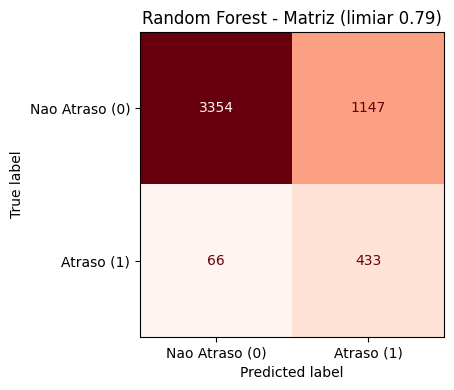

Resumo (teste):
- Limiar adotado: 0.79
- Precision atraso: 0.2741
- Recall atraso: 0.8677
- F2 atraso: 0.6054
- ROC-AUC atraso: 0.8785
- PR-AUC atraso: 0.4929


In [5]:

# Celula 5: treino final do Random Forest com os melhores hiperparametros + avaliacao no teste.
model_v2 = RandomForestClassifier(
    random_state=4242,
    n_jobs=-1,
    bootstrap=True,
    class_weight=None,
    **best_params_v2,
)

# Reajuste final somente no treino; o teste permanece intocado ate a avaliacao.
ros_final = RandomOverSampler(sampling_strategy="auto", random_state=42)
X_fit_final, y_fit_final = ros_final.fit_resample(X_train, y_train)
model_v2.fit(X_fit_final, y_fit_final)

# Probabilidade de atraso (classe 1).
y_proba_v2_train = model_v2.predict_proba(X_train)[:, 1]
y_proba_v2_test = model_v2.predict_proba(X_test)[:, 1]

# Mesmo threshold otimizado na validacao temporal.
y_pred_v2_train = (y_proba_v2_train >= best_threshold_v2).astype(int)
y_pred_v2_test = (y_proba_v2_test >= best_threshold_v2).astype(int)

res_v2_train = metricas_atraso(y_train, y_pred_v2_train, y_proba_v2_train)
res_v2_test = metricas_atraso(y_test, y_pred_v2_test, y_proba_v2_test)
metricas_treino_v2 = metricas_gerais(y_train, y_pred_v2_train, y_proba_v2_train)
metricas_teste_v2 = metricas_gerais(y_test, y_pred_v2_test, y_proba_v2_test)

print("Metricas no teste (foco em atraso):")
display(pd.DataFrame(pd.Series(res_v2_test, name="Teste")).round(4))

print("\nComo interpretar as metricas:")
print("- precision_atraso: entre os pedidos previstos como atraso, quantos realmente atrasaram.")
print("- recall_atraso: entre os pedidos que realmente atrasaram, quantos o modelo conseguiu detectar.")
print("- f1_atraso: media harmonica entre precision e recall.")
print("- f2_atraso: semelhante ao F1, mas dando mais peso ao recall.")
print("- roc_auc_atraso: capacidade de separar atraso vs nao atraso em todos os limiares.")
print("- pr_auc_atraso: qualidade do trade-off precision x recall para a classe rara.")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_v2_test,
    cmap="Reds",
    ax=ax,
    colorbar=False,
    display_labels=["Nao Atraso (0)", "Atraso (1)"],
)
ax.set_title(f"Random Forest - Matriz (limiar {best_threshold_v2:.2f})")
plt.tight_layout()
plt.show()

print("Resumo (teste):")
print(f"- Limiar adotado: {best_threshold_v2:.2f}")
print(f"- Precision atraso: {res_v2_test['precision_atraso']:.4f}")
print(f"- Recall atraso: {res_v2_test['recall_atraso']:.4f}")
print(f"- F2 atraso: {res_v2_test['f2_atraso']:.4f}")
print(f"- ROC-AUC atraso: {res_v2_test['roc_auc_atraso']:.4f}")
print(f"- PR-AUC atraso: {res_v2_test['pr_auc_atraso']:.4f}")


In [6]:
# Celula 6: tabelas de metricas de atraso (classe 1).
print("=" * 120)
print("METRICAS DE ATRASO (CLASSE 1)")
print("=" * 120)

print("\n(Accuracy, Precision, Recall, F1, F2, ROC-AUC, PR-AUC, Balanced Accuracy, MCC, Brier Score, Log Loss)")

print("\n" + "-" * 120)
print("TREINO (ATRASO)")
print("-" * 120)
df_v2_train_atraso = pd.DataFrame(pd.Series(res_v2_train, name="Treino"))
display(df_v2_train_atraso.round(4))

print("\n" + "-" * 120)
print("TESTE (ATRASO)")
print("-" * 120)
df_v2_test_atraso = pd.DataFrame(pd.Series(res_v2_test, name="Teste"))
display(df_v2_test_atraso.round(4))

# ============================================================================
# RESUMO
# ============================================================================
print("RESUMO\n")
print("─" * 120 + "\n")
print(f"  Limiar utilizado: {best_threshold_v2:.2f}")
print(
    f"  Treino - Accuracy: {metricas_treino_v2['Accuracy']:.4f}, ROC-AUC: {metricas_treino_v2['ROC-AUC']:.4f}, "
    f"Precision (Atraso): {res_v2_train['precision_atraso']:.4f}, Recall (Atraso): {res_v2_train['recall_atraso']:.4f}"
)
print(
    f"  Teste  - Accuracy: {metricas_teste_v2['Accuracy']:.4f}, ROC-AUC: {metricas_teste_v2['ROC-AUC']:.4f},"
    f"Precision (Atraso): {res_v2_test['precision_atraso']:.4f}, Recall (Atraso): {res_v2_test['recall_atraso']:.4f}"
)


METRICAS DE ATRASO (CLASSE 1)

(Accuracy, Precision, Recall, F1, F2, ROC-AUC, PR-AUC, Balanced Accuracy, MCC, Brier Score, Log Loss)

------------------------------------------------------------------------------------------------------------------------
TREINO (ATRASO)
------------------------------------------------------------------------------------------------------------------------


,Treino
accuracy_atraso,0.9518
precision_atraso,0.4633
recall_atraso,0.2670
f1_atraso,0.3388
f2_atraso,0.2917
roc_auc_atraso,0.8283
pr_auc_atraso,0.3313
balanced_accuracy_atraso,0.6260
mcc_atraso,0.3286
brier_score_atraso,0.1619



------------------------------------------------------------------------------------------------------------------------
TESTE (ATRASO)
------------------------------------------------------------------------------------------------------------------------


,Teste
accuracy_atraso,0.7574
precision_atraso,0.2741
recall_atraso,0.8677
f1_atraso,0.4165
f2_atraso,0.6054
roc_auc_atraso,0.8785
pr_auc_atraso,0.4929
balanced_accuracy_atraso,0.8065
mcc_atraso,0.3951
brier_score_atraso,0.3653


RESUMO

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

  Limiar utilizado: 0.79
  Treino - Accuracy: 0.9518, ROC-AUC: 0.8283, Precision (Atraso): 0.4633, Recall (Atraso): 0.2670
  Teste  - Accuracy: 0.7574, ROC-AUC: 0.8785,Precision (Atraso): 0.2741, Recall (Atraso): 0.8677


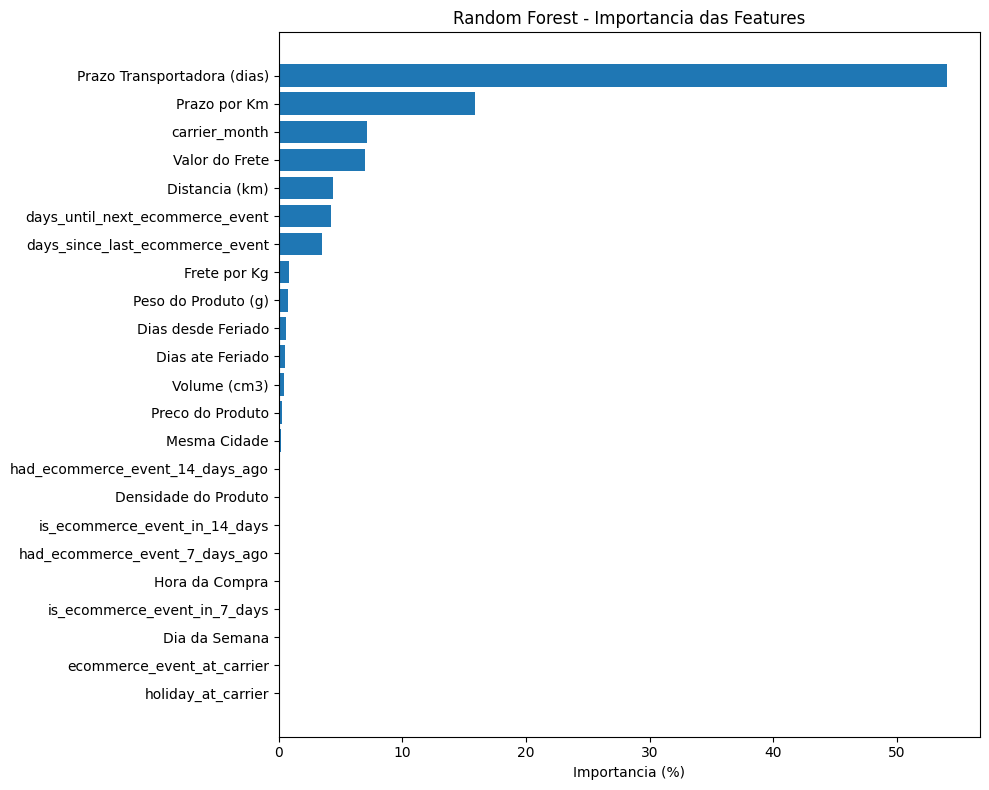


=== Resumo de importancia ===
  Prazo Transportadora (dias)               54.00%
  Prazo por Km                              15.90%
  carrier_month                              7.14%
  Valor do Frete                             6.95%
  Distancia (km)                             4.37%
  days_until_next_ecommerce_event            4.23%
  days_since_last_ecommerce_event            3.53%
  Frete por Kg                               0.81%
  Peso do Produto (g)                        0.75%
  Dias desde Feriado                         0.61%
  Dias ate Feriado                           0.54%
  Volume (cm3)                               0.41%
  Preco do Produto                           0.28%
  Mesma Cidade                               0.15%
  had_ecommerce_event_14_days_ago            0.14%
  Densidade do Produto                       0.12%
  is_ecommerce_event_in_14_days              0.03%
  had_ecommerce_event_7_days_ago             0.02%
  Hora da Compra                             0.01%


In [7]:

# Celula Extra: Importancia das Features do Random Forest.
import matplotlib.pyplot as plt
import pandas as pd

df_imp = pd.DataFrame({
    "feature": X_train.columns,
    "importance": model_v2.feature_importances_,
}).sort_values("importance", ascending=True)

df_imp["importance_pct"] = df_imp["importance"] / df_imp["importance"].sum() * 100

rename_map = {
    "prazo_transportadora_dias": "Prazo Transportadora (dias)",
    "distance_km": "Distancia (km)",
    "freight_value": "Valor do Frete",
    "price": "Preco do Produto",
    "product_weight_g": "Peso do Produto (g)",
    "volume_cm3": "Volume (cm3)",
    "same_city": "Mesma Cidade",
    "seller_city_encoded": "Cidade do Vendedor (Target Encoded)",
    "customer_city_encoded": "Cidade do Cliente (Target Encoded)",
    "prazo_por_km": "Prazo por Km",
    "frete_por_kg": "Frete por Kg",
    "densidade_produto": "Densidade do Produto",
    "purchase_hour": "Hora da Compra",
    "purchase_day_of_week": "Dia da Semana",
    "category_name_encoded": "Categoria do Produto",
    "days_until_next_holiday": "Dias ate Feriado",
    "days_since_last_holiday": "Dias desde Feriado",
    "purchase_month": "Mes da Compra",
}
df_imp["label"] = df_imp["feature"].map(rename_map).fillna(df_imp["feature"])

plt.figure(figsize=(10, 8))
plt.barh(df_imp["label"], df_imp["importance_pct"])
plt.xlabel("Importancia (%)")
plt.title("Random Forest - Importancia das Features")
plt.tight_layout()
plt.show()

print("\n=== Resumo de importancia ===")
df_imp_sorted = df_imp.sort_values("importance_pct", ascending=False)
for _, row in df_imp_sorted.iterrows():
    print(f"  {row['label']:40s} {row['importance_pct']:6.2f}%")


In [8]:
# Célula de exportação para deploy: modelo + pré-processamento completo.
# A API prevê no momento da coleta pela transportadora e recebe somente dados brutos.
import pickle

raw_columns = [
    "purchase_date", "purchase_time", "carrier_datetime", "estimated_delivery_datetime",
    "price", "freight_value", "product_weight_g", "height_cm", "width_cm", "length_cm",
    "distance_km", "same_city", "customer_city", "seller_city", "category_name",
]

artefato_modelo = {
    "modelo": model_v2,
    "balanceamento": best_balanceamento_v2,
    "hiperparametros": best_params_v2,
    "limiar": float(best_threshold_v2),
    "feature_names": list(X_train.columns),
    "num_cols": num_cols,
    "cat_cols": cat_cols,
    "scaler": scaler,
    "schema_version": 4,
    "inference_moment": "carrier_collection",
    "raw_columns": raw_columns,
    "ecommerce_events": [
        "mothers_day", "fathers_day", "children_day",
        "black_friday", "cyber_monday", "christmas",
    ],
}

with open("random_forest_lastmile_oversampling_model.pkl", "wb") as file:
    pickle.dump(artefato_modelo, file)

# CSV bruto para testar o mesmo contrato usado pela tela individual e pelo lote.
# Amostra organica e balanceada com 40% de atrasos (target=1) diluidos no tempo.
n_registros = 150
n_atrasos = int(n_registros * 0.40)   # 60 pedidos que atrasaram
n_no_prazo = n_registros - n_atrasos  # 90 pedidos no prazo

df_test_full = df.loc[test_mask].copy()
df_test_full["target_real_atraso"] = y_test.values

df_atrasos = df_test_full[df_test_full["target_real_atraso"] == 1]
df_no_prazo = df_test_full[df_test_full["target_real_atraso"] == 0]

# 1. 60 atrasos distribuidos uniformemente ao longo do periodo de teste
idx_atrasos = np.round(np.linspace(0, len(df_atrasos) - 1, n_atrasos)).astype(int)
selected_atrasos = df_atrasos.iloc[idx_atrasos]

# 2. 90 pedidos no prazo pareados temporalmente para diluir organicamente os atrasos
used_indices = set()
selected_no_prazo_indices = []

for dt in selected_atrasos["order_delivered_carrier_date"]:
    diffs = (df_no_prazo["order_delivered_carrier_date"] - dt).abs()
    for c in diffs.sort_values().index:
        if c not in used_indices:
            used_indices.add(c)
            selected_no_prazo_indices.append(c)
            break

for dt in selected_atrasos["order_delivered_carrier_date"][::2]:
    if len(selected_no_prazo_indices) >= n_no_prazo:
        break
    diffs = (df_no_prazo["order_delivered_carrier_date"] - dt).abs()
    for c in diffs.sort_values().index:
        if c not in used_indices:
            used_indices.add(c)
            selected_no_prazo_indices.append(c)
            break

selected_no_prazo = df_no_prazo.loc[selected_no_prazo_indices]

# 3. Concatena e ordena estritamente por ordem cronologica da coleta pela transportadora
test_rows = pd.concat([selected_atrasos, selected_no_prazo]).sort_values("order_delivered_carrier_date").reset_index(drop=True)

df_export = pd.DataFrame({
    "purchase_date": test_rows["order_purchase_timestamp"].dt.strftime("%Y-%m-%d"),
    "purchase_time": test_rows["order_purchase_timestamp"].dt.strftime("%H:%M"),
    "carrier_datetime": test_rows["order_delivered_carrier_date"].dt.strftime("%Y-%m-%dT%H:%M"),
    "estimated_delivery_datetime": test_rows["order_estimated_delivery_date"].dt.strftime("%Y-%m-%dT%H:%M"),
    "price": test_rows["price"],
    "freight_value": test_rows["freight_value"],
    "product_weight_g": test_rows["product_weight_g"],
    # A base não possui dimensões individuais; 1 × 1 × volume preserva o volume original.
    "height_cm": 1.0,
    "width_cm": 1.0,
    "length_cm": test_rows["volume_cm3"],
    "distance_km": test_rows["distance_km"],
    "same_city": test_rows["same_city"],
    "customer_city": test_rows["customer_city"].fillna("Unknown"),
    "seller_city": test_rows["seller_city"].fillna("Unknown"),
    "category_name": test_rows["category_name"].fillna("Unknown"),
    "target_real_atraso": test_rows["target_real_atraso"].values,
})

nome_arquivo_csv = f"amostra_teste_rf_oversampling_{n_registros}_pedidos.csv"
df_export.to_csv(nome_arquivo_csv, index=False)
df_export.to_csv("amostra_teste_rf_oversampling_100_pedidos.csv", index=False) # Compatibilidade

print("[Exportação] Artefato completo salvo: random_forest_lastmile_oversampling_model.pkl")
print(f"[Exportação] CSV bruto salvo: {nome_arquivo_csv} ({len(df_export)} pedidos: {df_export['target_real_atraso'].sum()} atrasos ({df_export['target_real_atraso'].mean():.0%}) e {(df_export['target_real_atraso'] == 0).sum()} no prazo)")

[Exportação] Artefato completo salvo: random_forest_lastmile_oversampling_model.pkl
[Exportação] CSV bruto salvo: amostra_teste_rf_oversampling_150_pedidos.csv (150 pedidos: 60 atrasos (40%) e 90 no prazo)
